What proportion of the studied items in each category are recalled? For each participant, the denominator counts eligible presentations in that category. A category with no eligible presentations has an undefined rate.

<div id="notebook-reference">

| Parameter | Meaning |
| ---------------------- | ------------------------------------------- |
| `data_paths`, `data_labels` | HDF5 response files and their labels, in matching order. Each file can contain observations or simulations. |
| `trial_queries`, `labels` | Trial selections and condition names in matching order. The queries apply to every file. Use `[None]` and `["All lists"]` for one unfiltered condition. |
| `comparison` | `"datasets"` compares files separately for each condition. `"conditions"` compares conditions from one file on the same axes. |
| `complete_lists_only` | Exclude lists with a padded study position before applying the analysis. |
| `max_subjects` | Maximum participants per file, starting with the lowest IDs. Zero includes everyone. |
| `category_field` | Dataset field giving the category at each study position. |
| `category_values` | Category codes to include, in display order. |
| `category_labels` | Names for those category codes, in the same order. |
| `valid_field` | Field with positive values at eligible presentations. |
| `paired_dataset` | Dataset label for paired contrasts. Defaults to the first file. |
| `comparisons` | Paired comparisons as (name, left condition, left category, right condition, right category), using zero-based indices. |
| `contrast_of_contrasts` | Differences of paired contrasts as (name, left A, left B, right A, right B). Each cell is a (condition, category) index pair. |
| `confidence_level`, `plot_seed` | Coverage and random seed for bootstrap intervals across participants. |
| `project_root` | Base directory for relative input and output paths. |
| `output_dir`, `figure_dir` | Output folder and optional separate folder for figures. |
| `figure_str` | Figure filename stem. Use an empty string to display figures without saving them. |
| `color_cycle`, `contrast_name` | Colors in display order and an optional legend title. |
| `ylim`, `yticks` | Optional vertical-axis limits and tick locations. |

Figures are saved under `results/cat_recall_rate/` by default. A single figure uses the supplied stem (`category_rates` by default). Multiple figures add a number and the comparison title to each filename. The output folder also receives `participant_category_rates.csv`, with one column per category. Requested paired contrasts appear in the notebook.

</div>

[Analysis reference](https://githubpsyche.github.io/jaxcmr/reference/analyses-cat_recall_rate.html)

## Configure this run

In [1]:
#| code-summary: "Input files, selections, and analysis settings"

from typing import Literal

type ComparisonMode = Literal["conditions", "datasets"]

data_paths = ["data/Dupertuys2026.h5"]
data_labels = ["Observed"]
trial_queries = ["data['list_type'] == 1", "data['list_type'] == 2", "data['list_type'] == 3"]
labels = ["Mixed", "Pure emotional", "Pure neutral"]
comparison: ComparisonMode = "conditions"
complete_lists_only = False
max_subjects = 0

category_field: str = "valence"
category_values = [-1, 0]
category_labels = ["Emotional", "Neutral"]
valid_field = "pres_itemnos"
paired_dataset = None
comparisons = []
contrast_of_contrasts = []
confidence_level = 0.95
plot_seed = 0

project_root = None
output_dir = "results/cat_recall_rate"
figure_dir = None
figure_str = "category_rates"
color_cycle = None
contrast_name = "Item category"
ylim = None
yticks = None

## Load data and select trials

Relative paths use the project directory. The [data guide](https://githubpsyche.github.io/jaxcmr/overview/data.html) describes the expected file format.

In [2]:
#| code-summary: "Install JAXCMR in Colab"

import sys

if "google.colab" in sys.modules:
    %pip install --upgrade "jaxcmr @ git+https://github.com/githubpsyche/jaxcmr.git@main"

In [3]:
#| code-summary: "Import analysis and plotting functions"

import csv
import re

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from jaxcmr.analyses.cat_recall_rate import plot_category_rates, subject_cat_recall_rate
from jaxcmr.analyses.statistics import compare_paired
from jaxcmr.dataset import select_conditions
from jaxcmr.examples import copy_example_inputs
from jaxcmr.helpers import load_data, resolve_project_path, resolve_project_root
from jaxcmr.plotting import add_analysis_legend, save_figure

In [4]:
#| code-summary: "Load response files"

root = resolve_project_root(project_root)
copy_example_inputs(data_paths, base_dir=root)
datasets = [
    load_data(resolve_project_path(path, root), max_subjects=max_subjects)
    for path in data_paths
]

Reusing matching input: data/Dupertuys2026.h5


In [5]:
#| code-summary: "Select trials for each condition"

masks_by_dataset = []
for dataset in datasets:
    selections = select_conditions(
        dataset, trial_queries, complete_lists_only=complete_lists_only
    )
    masks_by_dataset.append([selection.mask for selection in selections])

## Calculate participant recall rates

Each row records one participant’s proportion recalled in each category for a selected group of lists.

In [6]:
#| code-summary: "Calculate category rates for each participant"

rates_by_dataset = []
subjects_by_dataset = []
participant_rows = []
for dataset, dataset_label, condition_masks in zip(
    datasets, data_labels, masks_by_dataset, strict=True
):
    rates = []
    subjects = []
    for condition_label, condition_mask in zip(labels, condition_masks, strict=True):
        participant_scores = np.asarray(
            subject_cat_recall_rate(
                dataset,
                condition_mask,
                category_field,
                category_values,
                valid_field=valid_field,
            )
        )
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        rates.append(participant_scores)
        subjects.append(participant_ids)
        participant_rows.extend(
            (dataset_label, condition_label, subject, *row)
            for subject, row in zip(participant_ids, participant_scores, strict=True)
        )

    rates_by_dataset.append(rates)
    subjects_by_dataset.append(subjects)

In [7]:
#| code-summary: "Write participant rates by category"

destination = resolve_project_path(output_dir, root)
destination.mkdir(parents=True, exist_ok=True)
with (destination / "participant_category_rates.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["Dataset", "Condition", "Subject", *category_labels])
    writer.writerows(participant_rows)

## Compare paired category rates

Requested contrasts include participants with a defined rate in every cell of the comparison.

In [8]:
#| code-summary: "Match participant IDs for requested contrasts"

cells = {}
if comparisons or contrast_of_contrasts:
    index = data_labels.index(paired_dataset or data_labels[0])
    for condition_index, (subjects, rates) in enumerate(
        zip(subjects_by_dataset[index], rates_by_dataset[index], strict=True)
    ):
        for category_index in range(len(category_values)):
            cells[condition_index, category_index] = {
                int(subject): score
                for subject, score in zip(
                    subjects, rates[:, category_index], strict=True
                )
                if np.isfinite(score)
            }

In [9]:
#| code-summary: "Evaluate paired contrasts"

for label, left_trial, left_cat, right_trial, right_cat in comparisons:
    left, right = cells[left_trial, left_cat], cells[right_trial, right_cat]
    subjects = sorted(left.keys() & right.keys())
    print(
        label,
        compare_paired(
            np.array([left[s] for s in subjects]),
            np.array([right[s] for s in subjects]),
        ),
        sep="\n",
    )

In [10]:
#| code-summary: "Evaluate differences between paired contrasts"

for label, left_a, left_b, right_a, right_b in contrast_of_contrasts:
    parts = [
        cells[key]
        for key in [tuple(left_a), tuple(left_b), tuple(right_a), tuple(right_b)]
    ]
    subjects = sorted(set.intersection(*(set(part) for part in parts)))
    differences = np.array(
        [(parts[0][s] - parts[1][s]) - (parts[2][s] - parts[3][s]) for s in subjects]
    )
    print(
        label,
        compare_paired(differences, np.zeros_like(differences)),
        sep="\n",
    )
    if len(differences) > 1:
        interval = stats.t.interval(
            confidence_level,
            len(differences) - 1,
            loc=differences.mean(),
            scale=stats.sem(differences),
        )
        print(
            f"{confidence_level:.0%} interval for the difference of differences:",
            interval,
        )

## Plot recall rates by category

Each point averages the available participant rates for one category. Category colors are shared across groups.

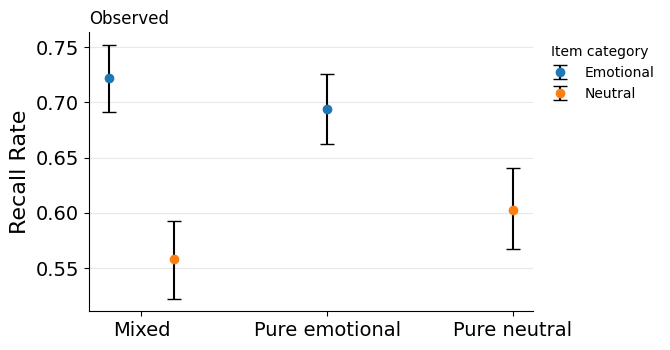

In [11]:
#| code-summary: "Draw the exported participant rates"

if comparison == "conditions":
    (only_file,) = rates_by_dataset
    groups = [(data_labels[0], labels, only_file)]
else:
    groups = [
        (condition, data_labels, [per_file[index] for per_file in rates_by_dataset])
        for index, condition in enumerate(labels)
    ]

for number, (title, group_labels, group_rates) in enumerate(groups, start=1):
    fig, ax = plt.subplots(figsize=(6.8, 3.6))
    plot_category_rates(
        ax,
        group_rates,
        group_labels,
        category_labels,
        color_cycle=color_cycle,
        confidence_level=confidence_level,
        bootstrap_seed=plot_seed,
    )
    ax.set_title(title, loc="left", fontsize=12)
    if ax.get_legend_handles_labels()[0]:
        add_analysis_legend(ax, contrast_name)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)

    if figure_str:
        suffix = None
        if len(groups) > 1:
            label = re.sub(r"\W+", "_", title.casefold()).strip("_")
            suffix = f"{number}_{label}".rstrip("_")
        save_figure(
            resolve_project_path(figure_dir or output_dir, root),
            figure_str,
            suffix=suffix,
            figure=fig,
        )
    else:
        fig.tight_layout()
    plt.show()
    plt.close(fig)